# Homework 6
## 1. Choropleth map
(a) Suppose we are interested in seeing what the pandemic years did to the perception of public
corruption. Compute the change in CPI from 2019 to 2021 and from 2021 to 2023 or 2025.

In [31]:
import pandas as pd

corruption = pd.read_csv("corruption.csv")
corruption = corruption.rename(columns={"Corruption Perceptions Index": "CPI"})
corruption["CPI"] = pd.to_numeric(corruption["CPI"], errors="coerce")

# One row per country, one column per year
wide = corruption.pivot_table(index=["Entity", "Code"], columns="Year", values="CPI")

# Use 2025 if available, otherwise fall back to 2023
later = wide[2025].fillna(wide[2023]) if 2025 in wide.columns else wide[2023]

changes = pd.DataFrame({
    "change_2019_2021": wide[2021] - wide[2019],
    "change_2021_later": later - wide[2021],
    "pct_change_2019_2021": (wide[2021] - wide[2019]) / wide[2019] * 100,
    "pct_change_2021_later": (later - wide[2021]) / wide[2021] * 100,
}).reset_index()

changes.head()
changes.to_csv("corruption_changes.csv", index=False)
changes

,Entity,Code,change_2019_2021,change_2021_later,pct_change_2019_2021,pct_change_2021_later
0,Afghanistan,AFG,0.0,4.0,0.000000,25.000000
1,Albania,ALB,0.0,2.0,0.000000,5.714286
2,Algeria,DZA,-2.0,3.0,-5.714286,9.090909
3,Angola,AGO,3.0,4.0,11.538462,13.793103
4,Argentina,ARG,-7.0,-1.0,-15.555556,-2.631579
...,...,...,...,...,...,...
177,Venezuela,VEN,-2.0,-1.0,-12.500000,-7.142857
178,Vietnam,VNM,2.0,2.0,5.405405,5.128205
179,Yemen,YEM,1.0,0.0,6.666667,0.000000
180,Zambia,ZMB,-1.0,4.0,-2.941176,12.121212


![(1b) World Corruption Perception](world_corruption.png)

![(1c) Southeast Asia Corruption Perception](SA_corruption.png)

## 2. US CBP Data

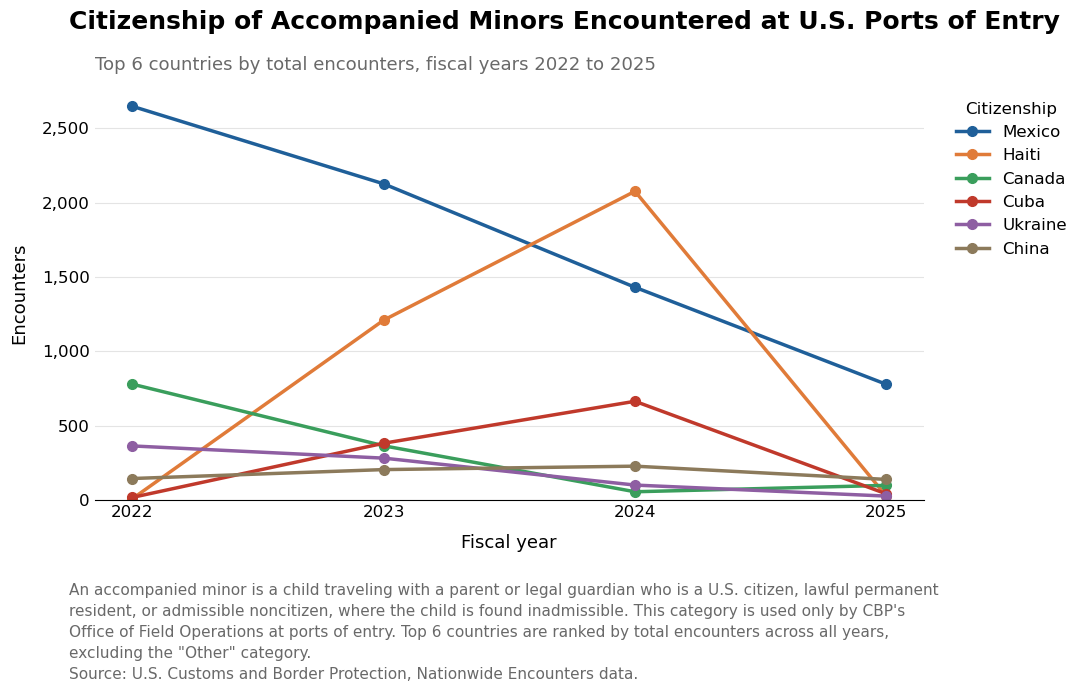

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter
import textwrap

# ---------- Data prep ----------
raw = pd.read_csv("encounters_aor.csv")

minors = raw[raw["Demographic"] == "Accompanied Minors"].copy()
minors["Citizenship"] = minors["Citizenship"].replace({"CHINA, PEOPLES REPUBLIC OF": "CHINA"})
minors["Fiscal Year"] = minors["Fiscal Year"].astype(str).str[:4].astype(int)

minors_grouped = (minors.groupby(["Citizenship", "Fiscal Year"])["Encounter Count"]
                  .sum().reset_index())

totals = (minors_grouped[minors_grouped["Citizenship"] != "OTHER"]
          .groupby("Citizenship")["Encounter Count"].sum())
top = totals.nlargest(6).index

# ---------- Plot ----------
plt.rcParams.update({"font.family": "sans-serif", "font.size": 12})
colors = ["#1f5f99", "#e07b39", "#3a9e5c", "#c0392b", "#8e5ea2", "#8c7a5b"]

fig, ax = plt.subplots(figsize=(11, 7))

for country, color in zip(top, colors):
    d = minors_grouped[minors_grouped["Citizenship"] == country].sort_values("Fiscal Year")
    ax.plot(d["Fiscal Year"], d["Encounter Count"], color=color,
            marker="o", markersize=7, linewidth=2.5, label=country.title())

# Titles
fig.suptitle("Citizenship of Accompanied Minors Encountered at U.S. Ports of Entry",
             x=0.07, ha="left", fontsize=18, fontweight="bold")
ax.set_title("Top 6 countries by total encounters, fiscal years 2022 to 2025",
             loc="left", fontsize=13, color="dimgray", pad=12)

# Axes
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(bottom=0)
ax.set_xlabel("Fiscal year", fontsize=13, labelpad=10)
ax.set_ylabel("Encounters", fontsize=13, labelpad=10)
ax.tick_params(labelsize=12, length=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color="lightgray", alpha=0.6)

# Legend
ax.legend(title="Citizenship", title_fontsize=12, fontsize=12,
          bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)

# Caption
note = ("An accompanied minor is a child traveling with a parent or legal guardian who is a "
        "U.S. citizen, lawful permanent resident, or admissible noncitizen, where the child is found "
        "inadmissible. This category is used only by CBP's Office of Field Operations at ports of entry. "
        "Top 6 countries are ranked by total encounters across all years, excluding the \"Other\" category.")
source = "Source: U.S. Customs and Border Protection, Nationwide Encounters data."

caption = textwrap.fill(note, width=115) + "\n" + source
fig.text(0.07, 0.02, caption, ha="left", va="bottom",
         fontsize=11, color="dimgray", linespacing=1.5)

plt.tight_layout(rect=[0, 0.18, 1, 1])   # reserve bottom 18% for the caption
plt.savefig("accompanied_minors.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
# Top citizenship in each area of responsibility (AOR)
aor = (minors[minors["Citizenship"] != "OTHER"]
       .groupby(["AOR (Abbv)", "Citizenship"])["Encounter Count"]
       .sum().reset_index())
aor = aor.sort_values(["AOR (Abbv)", "Encounter Count"], ascending=[True, False])
top_aor = aor.groupby("AOR (Abbv)").head(1).reset_index(drop=True)
top_aor = top_aor.rename(columns={"Encounter Count": "Total Encounters"})
top_aor.to_csv("top_citizenship_by_aor.csv", index=False)
top_aor

,AOR (Abbv),Citizenship,Total Encounters
0,Atlanta,UKRAINE,27
1,Baltimore,UKRAINE,25
2,Boston,CANADA,116
3,Buffalo,CANADA,970
4,Chicago,UKRAINE,131
5,Detroit,CANADA,88
6,El Paso,MEXICO,717
7,Houston,NICARAGUA,95
8,Laredo,MEXICO,3452
9,Los Angeles,NICARAGUA,45


![Accompanied Minors Choropleth](AMC.png)

## AI Statement
I used Claude. For the corruption perceptions maps, Claude helped me debug my pandas code and reshape the data with pivot_table. It also gave feedback on my Datawrapper maps, helping to write titles, descriptions, legend labels, and alt text. For part (c), Claude helped me create a custom Southeast Asia GeoJSON with geopandas so I could change the projection. For the CBP problem, Claude helped fix a KeyError and clean up my line chart, correct geocoding errors on my symbol map, and format the figure caption.